# Day 10: Sampling Distribution, CLT, Standard Error & Confidence Intervals

## Learning Objectives

- Understand sampling distribution.
- Understand the Central Limit Theorem (CLT).
- Calculate and interpret Standard Error.
- Understand Confidence Intervals.
- Calculate confidence intervals using Python.
- Apply these concepts to real-world business problems.

**Libraries:** NumPy, Pandas, Matplotlib, Seaborn, SciPy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

sns.set_theme(style="whitegrid")

## 1. Population, Sample and Sampling Distribution

**Population:** The complete group we want to study.

**Sample:** A subset selected from the population.

**Sampling Distribution:** The probability distribution of a sample statistic, such as the sample mean, calculated from all possible samples of the same size.

Example:
- Population: All customers of an e-commerce company.
- Sample: 100 customers selected from the population.
- Sample statistic: Average purchase amount of those 100 customers.
- Sampling distribution: Distribution of sample means obtained from repeatedly selecting samples of 100 customers.

Important: A sampling distribution is different from the distribution of individual population observations.

In [2]:
np.random.seed(42)

population = np.random.normal(
    loc=500,
    scale=100,
    size=10000
)

population_mean = np.mean(population)
population_std = np.std(population, ddof=0)

print("Population Size:", len(population))
print("Population Mean:", round(population_mean, 2))
print("Population Standard Deviation:", round(population_std, 2))

Population Size: 10000
Population Mean: 499.79
Population Standard Deviation: 100.34


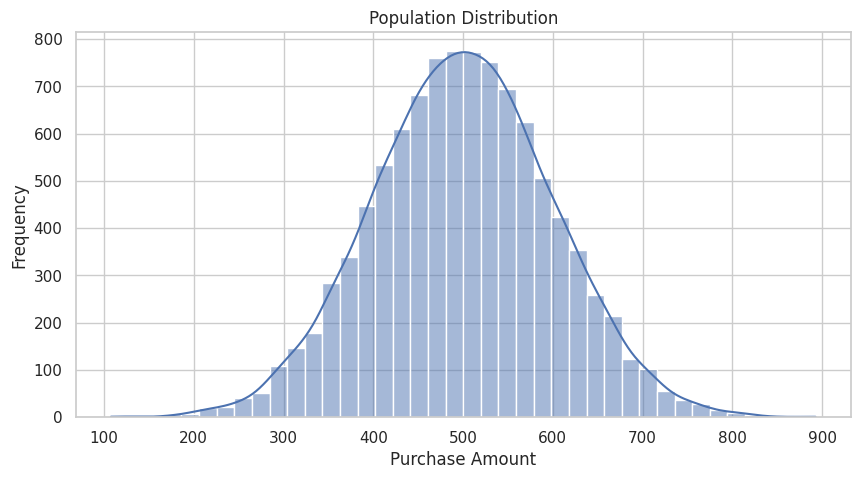

In [3]:
plt.figure(figsize=(10, 5))

sns.histplot(
    population,
    bins=40,
    kde=True
)

plt.title("Population Distribution")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")

plt.show()

## 2. Generate a Sampling Distribution

We will repeatedly select samples from the population.

For each sample:
1. Select 50 observations.
2. Calculate the sample mean.
3. Store the sample mean.

After repeating this process many times, we get a sampling distribution of sample means.

In [4]:
np.random.seed(42)

sample_size = 50
number_of_samples = 1000

sample_means = []

for _ in range(number_of_samples):

    sample = np.random.choice(
        population,
        size=sample_size,
        replace=True
    )

    sample_means.append(np.mean(sample))

sample_means = np.array(sample_means)

print("Number of Sample Means:", len(sample_means))
print("Mean of Sample Means:", round(sample_means.mean(), 2))

Number of Sample Means: 1000
Mean of Sample Means: 500.27


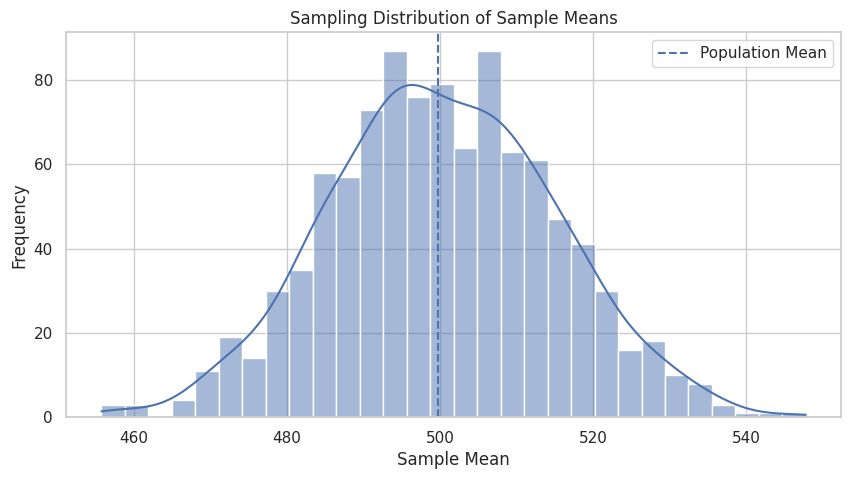

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    sample_means,
    bins=30,
    kde=True
)

plt.axvline(
    population_mean,
    linestyle="--",
    label="Population Mean"
)

plt.title("Sampling Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.legend()

plt.show()

## 3. Central Limit Theorem (CLT)

The Central Limit Theorem states:

When sufficiently large random samples are repeatedly selected from a population, the sampling distribution of the sample mean tends to become approximately normal, regardless of the original population distribution, under suitable conditions.

Important points:
- Samples should be randomly selected.
- Observations should be independent (or the sampling design should account for dependence).
- The population should have a finite mean and variance.
- Larger sample sizes generally produce a more normal sampling distribution.

The CLT is important because it allows analysts to use normal-based statistical methods in many situations.

Note: A sample size of 30 is a common guideline, not a universal guarantee. The required sample size depends on the population distribution and the analysis.

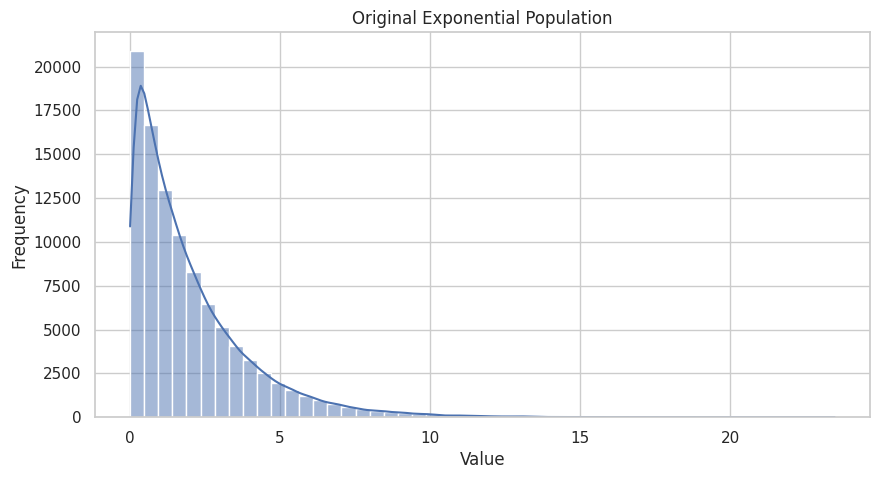

In [6]:
np.random.seed(42)

skewed_population = np.random.exponential(
    scale=2,
    size=100000
)

plt.figure(figsize=(10, 5))

sns.histplot(
    skewed_population,
    bins=50,
    kde=True
)

plt.title("Original Exponential Population")
plt.xlabel("Value")
plt.ylabel("Frequency")

plt.show()

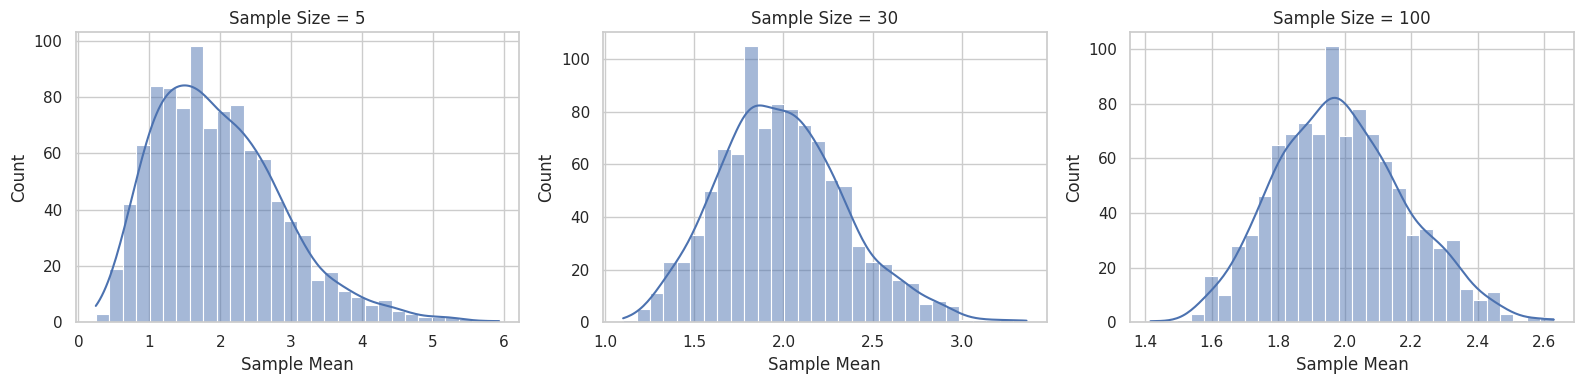

In [7]:
np.random.seed(42)

sample_sizes = [5, 30, 100]
number_of_samples = 1000

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4)
)

for ax, size in zip(axes, sample_sizes):

    means = []

    for _ in range(number_of_samples):

        sample = np.random.choice(
            skewed_population,
            size=size,
            replace=True
        )

        means.append(np.mean(sample))

    sns.histplot(
        means,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Sample Size = {size}")
    ax.set_xlabel("Sample Mean")

plt.tight_layout()
plt.show()

## 4. Standard Error (SE)

Standard Error measures the variability of a sample statistic across repeated samples.

For the sample mean:

Standard Error = Population Standard Deviation / √Sample Size

When population standard deviation is unknown, we estimate it using the sample standard deviation:

Estimated Standard Error = Sample Standard Deviation / √Sample Size

Important differences:

- Standard Deviation measures the spread of individual observations.
- Standard Error measures the variability of a sample statistic, such as the sample mean.

As sample size increases, the Standard Error generally decreases.

In [8]:
sample = np.random.choice(
    population,
    size=100,
    replace=True
)

sample_mean = np.mean(sample)
sample_std = np.std(sample, ddof=1)

standard_error = sample_std / np.sqrt(len(sample))

print("Sample Mean:", round(sample_mean, 2))
print("Sample Standard Deviation:", round(sample_std, 2))
print("Standard Error:", round(standard_error, 2))

Sample Mean: 494.18
Sample Standard Deviation: 101.9
Standard Error: 10.19


In [9]:
sample_sizes = [10, 30, 50, 100, 500, 1000]

results = []

for size in sample_sizes:

    sample = np.random.choice(
        population,
        size=size,
        replace=True
    )

    sample_std = np.std(sample, ddof=1)

    standard_error = sample_std / np.sqrt(size)

    results.append({
        "Sample Size": size,
        "Standard Error": standard_error
    })

se_df = pd.DataFrame(results)

se_df

,Sample Size,Standard Error
0,10,29.768340
1,30,18.081602
2,50,15.930471
3,100,11.210292
4,500,4.659329
5,1000,3.118963


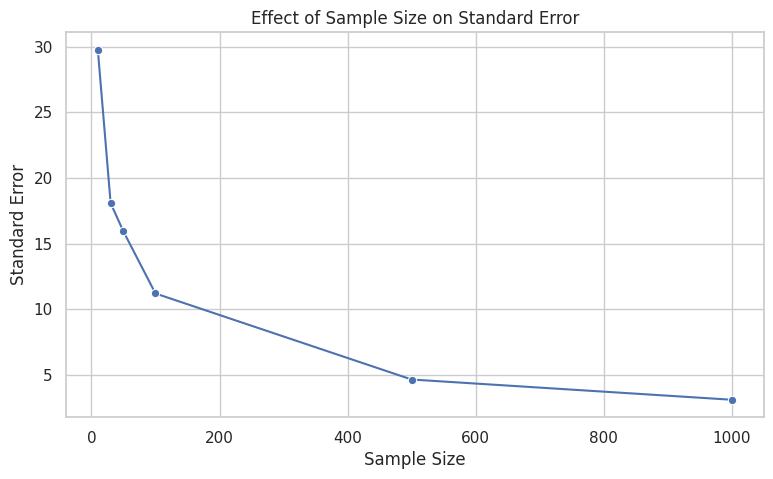

In [10]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=se_df,
    x="Sample Size",
    y="Standard Error",
    marker="o"
)

plt.title("Effect of Sample Size on Standard Error")
plt.xlabel("Sample Size")
plt.ylabel("Standard Error")

plt.show()

## 5. Confidence Interval (CI)

A Confidence Interval is a range of values used to estimate an unknown population parameter.

For example, instead of reporting only an average customer purchase amount of ₹500, we may estimate a range within which the population mean is plausibly located.

A 95% confidence interval means that if we repeatedly collected samples and constructed intervals using the same method, approximately 95% of those intervals would contain the true population parameter.

Important:
A 95% confidence interval does not mean there is a 95% probability that the fixed population mean lies inside one already-calculated interval.

For a mean with unknown population standard deviation, we commonly use the t-distribution:

Confidence Interval = Sample Mean ± t Critical Value × Standard Error

In [11]:
np.random.seed(42)

sample = np.random.choice(
    population,
    size=100,
    replace=True
)

sample_mean = np.mean(sample)
sample_std = np.std(sample, ddof=1)
sample_size = len(sample)

standard_error = sample_std / np.sqrt(sample_size)

confidence_level = 0.95
degrees_of_freedom = sample_size - 1

t_critical = stats.t.ppf(
    (1 + confidence_level) / 2,
    df=degrees_of_freedom
)

margin_of_error = t_critical * standard_error

lower_limit = sample_mean - margin_of_error
upper_limit = sample_mean + margin_of_error

print("Sample Mean:", round(sample_mean, 2))
print("Standard Error:", round(standard_error, 2))
print("Margin of Error:", round(margin_of_error, 2))

print(
    "95% Confidence Interval:",
    (round(lower_limit, 2), round(upper_limit, 2))
)

Sample Mean: 494.97
Standard Error: 10.36
Margin of Error: 20.55
95% Confidence Interval: (np.float64(474.42), np.float64(515.52))


## 6. Confidence Interval at Different Confidence Levels

Common confidence levels:

- 90% Confidence Level
- 95% Confidence Level
- 99% Confidence Level

As the confidence level increases, the confidence interval generally becomes wider.

This happens because we need a wider range to achieve a higher confidence level.

In [12]:
confidence_levels = [0.90, 0.95, 0.99]

ci_results = []

for confidence in confidence_levels:

    t_critical = stats.t.ppf(
        (1 + confidence) / 2,
        df=degrees_of_freedom
    )

    margin = t_critical * standard_error

    ci_results.append({
        "Confidence Level": f"{confidence * 100:.0f}%",
        "Lower Limit": sample_mean - margin,
        "Upper Limit": sample_mean + margin,
        "Interval Width": 2 * margin
    })

ci_df = pd.DataFrame(ci_results)

ci_df.round(2)

,Confidence Level,Lower Limit,Upper Limit,Interval Width
0,90%,477.78,512.17,34.39
1,95%,474.42,515.52,41.10
2,99%,467.77,522.17,54.40


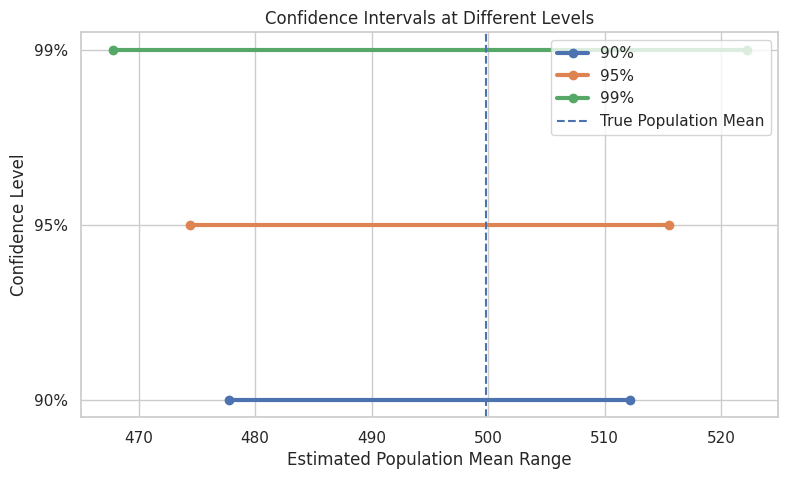

In [13]:
plt.figure(figsize=(9, 5))

for index, row in ci_df.iterrows():

    plt.plot(
        [row["Lower Limit"], row["Upper Limit"]],
        [index, index],
        marker="o",
        linewidth=3,
        label=row["Confidence Level"]
    )

plt.axvline(
    population_mean,
    linestyle="--",
    label="True Population Mean"
)

plt.yticks(
    range(len(ci_df)),
    ci_df["Confidence Level"]
)

plt.title("Confidence Intervals at Different Levels")
plt.xlabel("Estimated Population Mean Range")
plt.ylabel("Confidence Level")
plt.legend()

plt.show()

## 7. Business Applications

### E-commerce
Estimate the average purchase amount of all customers using a representative sample.

### Banking
Estimate average loan amounts or customer repayment behavior using sample data.

### Marketing
Use confidence intervals to estimate customer satisfaction or campaign response rates.

### Retail
Estimate average daily sales across stores by analyzing selected store samples.

### Operations
Use sampling distributions to understand uncertainty in average delivery times.

These methods help analysts make data-driven decisions while understanding uncertainty.

## 8. Quick Revision

| Concept | Meaning |
|---|---|
| Sampling Distribution | Distribution of a sample statistic across repeated samples |
| CLT | Sampling distribution of the mean tends to become approximately normal under suitable conditions |
| Standard Deviation | Spread of individual observations |
| Standard Error | Variability of a sample statistic |
| Confidence Interval | Range of plausible values for a population parameter |
| Margin of Error | Amount added and subtracted from the estimate to form an interval |

## 9. Interview Questions and Answers

**Q1. What is a sampling distribution?**  
It is the probability distribution of a sample statistic, such as the sample mean, across repeated samples.

**Q2. What is the Central Limit Theorem?**  
It states that the sampling distribution of the sample mean tends to become approximately normal as sample size increases, under suitable conditions.

**Q3. What is Standard Error?**  
Standard Error measures the variability of a sample statistic across repeated samples.

**Q4. What is the difference between Standard Deviation and Standard Error?**  
Standard Deviation measures the spread of individual observations, while Standard Error measures the variability of a sample statistic.

**Q5. What happens to Standard Error when sample size increases?**  
It generally decreases because Standard Error is inversely proportional to the square root of sample size.

**Q6. What is a Confidence Interval?**  
It is a range of values used to estimate an unknown population parameter.

**Q7. What does a 95% Confidence Interval mean?**  
If we repeatedly take samples and construct intervals using the same method, approximately 95% of those intervals will contain the true population parameter.

**Q8. Why do we use the t-distribution for a confidence interval of the mean?**  
We commonly use it when the population standard deviation is unknown and we estimate it using the sample standard deviation.

**Q9. What happens when the confidence level increases?**  
The confidence interval generally becomes wider.

**Q10. Does a larger sample size always eliminate sampling error?**  
No. A larger sample generally reduces sampling variability, but it does not eliminate sampling error or selection bias.

## 10. Practice Tasks

1. Create a population of 20,000 observations using an exponential distribution.
2. Generate 500 sample means using a sample size of 40.
3. Plot the sampling distribution of sample means.
4. Compare the sampling distributions for sample sizes 10, 30, 50 and 100.
5. Calculate the Standard Error for a sample of 200 observations.
6. Calculate 90%, 95% and 99% confidence intervals for a sample mean.
7. Explain why the 99% confidence interval is generally wider than the 90% interval.
8. Explain the difference between Standard Deviation and Standard Error using a business example.

Try to solve these tasks independently before checking any solution.

## Day 10 — Key Takeaways

- A sampling distribution describes the behavior of a sample statistic across repeated samples.
- The Central Limit Theorem explains why sample means tend to follow an approximately normal distribution under suitable conditions.
- Standard Error measures the variability of a sample statistic.
- Larger sample sizes generally reduce Standard Error.
- Confidence Intervals help estimate population parameters while expressing uncertainty.
- Higher confidence levels generally produce wider intervals.

### Next Topic: Day 11
Hypothesis Testing, Null and Alternative Hypotheses, Z-Test and T-Test.